# Quant Kraken research framework

Run all cells from a fresh Python kernel. The default uses **synthetic data** to verify mechanics, not profitability. No network, credentials or exchange orders are used. The configured test period remains locked.

This notebook reuses validated snapshots, the shared research/paper strategy interface, funded next-open execution, registered trials and existing metrics. Legacy TWSQ Alpha compatibility is covered by the repository tests; legacy same-close accounting is not used (see `docs/backtest_core.md`).

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "kraken_quant" / "experiment.py").is_file():
    ROOT = ROOT.parent
assert (ROOT / "kraken_quant" / "experiment.py").is_file(), "Launch from the repository or notebooks directory"
sys.path.insert(0, str(ROOT))
import json
import subprocess
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from kraken_quant.config import CONFIG
from kraken_quant.notebook_research import synthetic_history, load_local_history
from kraken_quant.experiment import ParameterRegistry, run_experiment
from kraken_quant.research_execution import ResearchCosts, run_research, research_buy_and_hold
from kraken_quant.strategies import multi_factory
from kraken_quant.strategy import StrategyPipeline
print("Repository:", ROOT)
display(pd.DataFrame([vars(s) for s in CONFIG.splits]))

Repository: C:\Users\avyas\kraken_quant


,name,start,end
0,train,2020-08-11 00:00:00+00:00,2023-12-31 00:00:00+00:00
1,validation,2024-01-01 00:00:00+00:00,2024-12-31 00:00:00+00:00
2,test,2025-01-01 00:00:00+00:00,2026-09-30 00:00:00+00:00


## Inputs and preregistration

Keep `SNAPSHOT_DIRECTORY = None` for the reproducible fixture. For historical work, supply a repository-relative directory containing `HistoricalSnapshot.write` JSON artifacts for every configured asset, ending no later than validation. Set train/validation windows within their locked splits and ensure sufficient warm-up coverage. Source venue and quote currency remain visible in the manifest; synthetic inputs are never labelled Kraken observations.

Hypothesis: positive momentum under a positive BTC regime and a volatility ceiling merits further investigation. The small grid below is disclosed in advance; it does not select a winning strategy or release the test set. Fees, spread and slippage are scenario assumptions, not current exchange quotes.

In [2]:
SNAPSHOT_DIRECTORY = None
SEED = 7
WINDOWS = {"train": ("2023-12-01", "2023-12-31"),
           "validation": ("2024-01-01", "2024-02-29")}
WARMUP_DAYS = 60
history = synthetic_history(SEED) if SNAPSHOT_DIRECTORY is None else load_local_history(ROOT, SNAPSHOT_DIRECTORY)
DATA_LABEL = "SYNTHETIC ? mechanics only" if SNAPSHOT_DIRECTORY is None else "LOCAL SNAPSHOTS ? exploratory research"
print(DATA_LABEL)
display(pd.DataFrame([vars(m) for m in history.manifests.values()]))
revision = subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip()
registry = ParameterRegistry(ROOT / ".notebook-runtime" / "trials")
costs = ResearchCosts(fee_rate=0.002, spread_rate=0.001, slippage_rate=0.0005)
parameters = dict(lookback=15, regime_days=30, volatility_days=20, annual_vol_limit=1.0, budget=0.8)
trials = [registry.register("Momentum under BTC regime: notebook demonstration", "multi-asset-momentum",
    dict(parameters, lookback=lookback), code_revision=revision, seed=SEED,
    input_hashes={str(k): m.sha256 for k, m in history.manifests.items()})
    for lookback in (10, 15, 20)]
assert len(trials) == 3

SYNTHETIC ? mechanics only


,version,symbol,source,source_symbol,frequency,start,end,rows,sha256
0,1,BTC/USD,synthetic,BTC/USD,1d,2023-10-01T00:00:00+00:00,2024-02-29T00:00:00+00:00,152,e09aa03c02b7401327c3f06f38c6489f31be12d1c382c5...
1,1,ETH/USD,synthetic,ETH/USD,1d,2023-10-01T00:00:00+00:00,2024-02-29T00:00:00+00:00,152,1af6981a85a9fc73db8e03f60f7702f69f3f8cac555adf...
2,1,XRP/USD,synthetic,XRP/USD,1d,2023-10-01T00:00:00+00:00,2024-02-29T00:00:00+00:00,152,a1f96e58307ad34cd3cf9a94a48a32323bbaa42429226f...
3,1,SOL/USD,synthetic,SOL/USD,1d,2023-10-01T00:00:00+00:00,2024-02-29T00:00:00+00:00,152,948a8963339977d9b273c3d249506cbe9d3c80697cfe5f...
4,1,ADA/USD,synthetic,ADA/USD,1d,2023-10-01T00:00:00+00:00,2024-02-29T00:00:00+00:00,152,3707a4975c9ded2a11b422b12da5a623a29acb3a3f5d82...


In [3]:
experiments = [run_experiment(trial, history, multi_factory, windows=WINDOWS,
    costs=costs, warmup_days=WARMUP_DAYS) for trial in trials]
comparison = pd.concat([result.table for result in experiments], ignore_index=True)
comparison.insert(0, "data_label", DATA_LABEL)
display(comparison)
# Every experiment contains train/validation strategy and cost-matched buy-and-hold metrics.
assert set(comparison.split) == {"train", "validation"}
assert {"sharpe", "sortino", "fees", "slippage_cost", "spread_cost",
        "turnover", "trade_count", "max_drawdown", "benchmark_total_return"} <= set(comparison)
assert all(json.loads(r.manifest)["inputs"]["test_access"] == "locked" for r in experiments)

,data_label,trial_id,hypothesis,strategy,parameters,split,seed,start,end,total_return,...,benchmark_sharpe,benchmark_sortino,benchmark_max_drawdown,benchmark_turnover,benchmark_trade_count,benchmark_fees,benchmark_slippage_cost,benchmark_spread_cost,benchmark_financing_cost,benchmark_relative_return
0,SYNTHETIC ? mechanics only,b59fab6a4bae554b2cbe500f2661c33a02de62a1503628...,Momentum under BTC regime: notebook demonstration,multi-asset-momentum,"{""annual_vol_limit"":1.0,""budget"":0.8,""lookback...",train,7,2023-12-01T00:00:00+00:00,2023-12-31T00:00:00+00:00,-0.016741,...,1.810665,2.694652,0.024086,0.988236,5,1.996008,0.498503,0.498503,0.0,-0.032563
1,SYNTHETIC ? mechanics only,b59fab6a4bae554b2cbe500f2661c33a02de62a1503628...,Momentum under BTC regime: notebook demonstration,multi-asset-momentum,"{""annual_vol_limit"":1.0,""budget"":0.8,""lookback...",validation,7,2024-01-01T00:00:00+00:00,2024-02-29T00:00:00+00:00,-0.000006,...,-1.637333,-2.257562,0.086462,0.992486,5,1.996008,0.498503,0.498503,0.0,0.031989
2,SYNTHETIC ? mechanics only,cac6a45c516bd7f91784f741f7540a361421af23636257...,Momentum under BTC regime: notebook demonstration,multi-asset-momentum,"{""annual_vol_limit"":1.0,""budget"":0.8,""lookback...",train,7,2023-12-01T00:00:00+00:00,2023-12-31T00:00:00+00:00,-0.017329,...,1.810665,2.694652,0.024086,0.988236,5,1.996008,0.498503,0.498503,0.0,-0.033150
3,SYNTHETIC ? mechanics only,cac6a45c516bd7f91784f741f7540a361421af23636257...,Momentum under BTC regime: notebook demonstration,multi-asset-momentum,"{""annual_vol_limit"":1.0,""budget"":0.8,""lookback...",validation,7,2024-01-01T00:00:00+00:00,2024-02-29T00:00:00+00:00,-0.002725,...,-1.637333,-2.257562,0.086462,0.992486,5,1.996008,0.498503,0.498503,0.0,0.029270
4,SYNTHETIC ? mechanics only,9eb67483b602ed0aad32e185f8cdc66c5688465b838016...,Momentum under BTC regime: notebook demonstration,multi-asset-momentum,"{""annual_vol_limit"":1.0,""budget"":0.8,""lookback...",train,7,2023-12-01T00:00:00+00:00,2023-12-31T00:00:00+00:00,-0.014812,...,1.810665,2.694652,0.024086,0.988236,5,1.996008,0.498503,0.498503,0.0,-0.030633
5,SYNTHETIC ? mechanics only,9eb67483b602ed0aad32e185f8cdc66c5688465b838016...,Momentum under BTC regime: notebook demonstration,multi-asset-momentum,"{""annual_vol_limit"":1.0,""budget"":0.8,""lookback...",validation,7,2024-01-01T00:00:00+00:00,2024-02-29T00:00:00+00:00,0.005041,...,-1.637333,-2.257562,0.086462,0.992486,5,1.996008,0.498503,0.498503,0.0,0.037035


## Equity, drawdown and cross-asset diagnostics

Use the middle preregistered specification for illustration, regardless of its ranking. Fresh strategy instances are used for each run. Decisions use completed bars; trades fill at the following open. Final holdings are marked without a forced liquidation. Warm-up is excluded from scored returns.

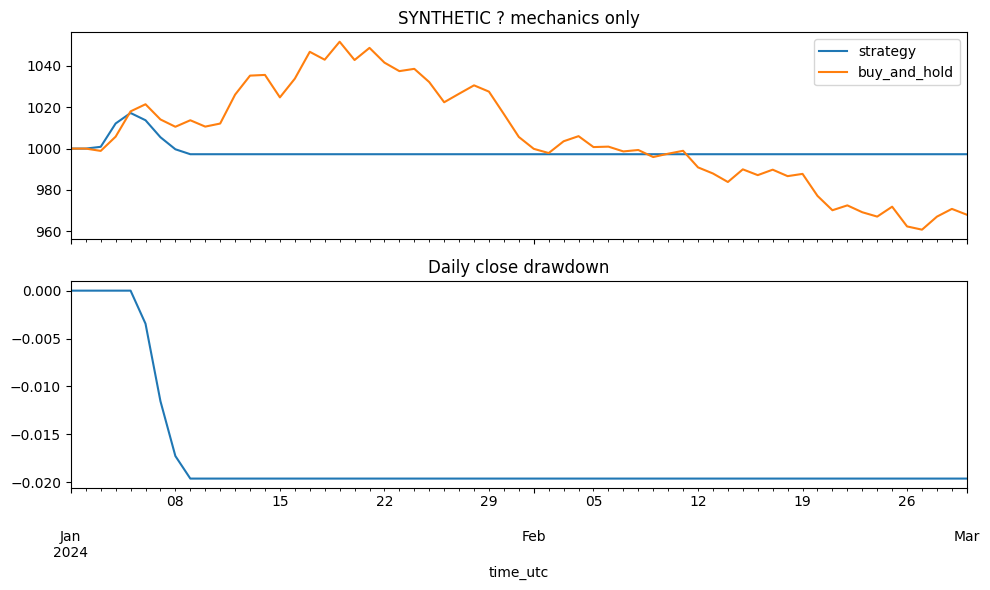

,venue,symbol,close_return,fills,fees,final_quantity
0,synthetic,ADA/USD,0.008479,7,1.092805,0.0
1,synthetic,BTC/USD,-0.128659,7,1.074209,0.0
2,synthetic,ETH/USD,-0.054460,3,0.810111,0.0
3,synthetic,SOL/USD,-0.067039,7,1.096037,0.0
4,synthetic,XRP/USD,0.096236,0,0.000000,0.0


In [4]:
args = dict(split="validation", start=WINDOWS["validation"][0], end=WINDOWS["validation"][1],
            costs=costs, warmup_days=WARMUP_DAYS)
result = run_research(history, StrategyPipeline(multi_factory(parameters, SEED)), **args)
benchmark = research_buy_and_hold(history, **args)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
pd.DataFrame({"strategy": result.equity, "buy_and_hold": benchmark.equity}).plot(ax=axes[0], title=DATA_LABEL)
(result.equity / result.equity.cummax() - 1).plot(ax=axes[1], title="Daily close drawdown")
plt.tight_layout()
plt.show()
asset_rows = []
for instrument in history.instruments:
    # Keep full-universe context for BTC regime; isolate P&L contribution by holdings.
    frame = history.window(instrument, split="validation", start=args["start"], end=args["end"],
        decision_time=pd.Timestamp(args["end"], tz="UTC") + pd.Timedelta(days=1))
    asset_rows.append(dict(venue=instrument.venue, symbol=instrument.symbol,
        close_return=frame.close.iloc[-1] / frame.close.iloc[0] - 1,
        fills=sum(f.instrument == instrument for f in result.fills),
        fees=sum(f.fee for f in result.fills if f.instrument == instrument),
        final_quantity=result.positions[instrument].iloc[-1]))
display(pd.DataFrame(asset_rows))

In [5]:
stress_rows = []
for multiplier in (1, 2, 3):
    stressed_costs = ResearchCosts(fee_rate=costs.fee_rate * multiplier,
        spread_rate=costs.spread_rate * multiplier, slippage_rate=costs.slippage_rate * multiplier)
    stressed = run_research(history, StrategyPipeline(multi_factory(parameters, SEED)),
        **dict(args, costs=stressed_costs))
    stress_rows.append(dict(cost_multiplier=multiplier, **stressed.metrics()))
display(pd.DataFrame(stress_rows))
try:
    run_experiment(trials[1], history, multi_factory, windows={"test": (CONFIG.split("test").start, CONFIG.split("test").end)})
except PermissionError:
    print("Verified: test-period experiment rejected before strategy execution.")
else:
    raise AssertionError("Locked test access unexpectedly succeeded")
# Verify deterministic experiment identity and table reproduction.
repeated = run_experiment(trials[1], history, multi_factory, windows=WINDOWS,
                          costs=costs, warmup_days=WARMUP_DAYS)
assert repeated.run_id == experiments[1].run_id
pd.testing.assert_frame_equal(repeated.table, experiments[1].table)
print("Verified: reproducible registered experiment.")

,cost_multiplier,total_return,annualized_volatility,sharpe,sortino,max_drawdown,turnover,trade_count,fees,slippage_cost,spread_cost,financing_cost
0,1,-0.002725,0.040869,-0.386150,-0.591716,0.019608,2.039823,24,4.073163,1.018292,1.018292,0.0
1,2,-0.008807,0.043648,-1.211395,-1.706620,0.023183,2.048096,24,8.132989,2.033254,2.033254,0.0
2,3,-0.014869,0.047874,-1.879856,-2.439109,0.026750,2.056426,24,12.179468,3.044882,3.044882,0.0


Verified: test-period experiment rejected before strategy execution.


Verified: reproducible registered experiment.


## Interpretation and artifacts

These default outputs validate integration only. They provide no historical or live evidence of profitability. Cross-asset price changes and holdings above are diagnostics, not independent asset strategy returns. Daily-close risk, full fills, constant costs and optimistic next-open latency limit the simulation. The fixed current universe also cannot establish absence of historical selection bias.

Historical findings require audited source data, training-only fitting, disclosed trial history, sensitivity and cross-asset investigation, and a separately authorized frozen-specification test evaluation. Test results are deliberately unavailable here. Registered experiment manifests include input and engine hashes, costs, windows and environment versions. Re-running does not overwrite immutable published artifacts.

In [6]:
WRITE_ARTIFACTS = False
if WRITE_ARTIFACTS:
    for experiment in experiments:
        destination = ROOT / ".notebook-runtime" / "results" / experiment.run_id
        if not destination.exists():
            experiment.write(destination.parent)
print("Notebook completed:", DATA_LABEL, "| test access locked")

Notebook completed: SYNTHETIC ? mechanics only | test access locked
